# CyberMCP V1.2 — Asistente NLP con MCP, LLM y LangChain
**Versión con visualizaciones adicionales:** EDA, calidad del catálogo, tiempos MCP, recuperación TF-IDF y latencia de generación.
**Mini proyecto original de NLP · Google Colab · versión académica**

**Pregunta de investigación:** ¿Puede un asistente dotado de herramientas MCP consultar de manera verificable el catálogo público CISA KEV y generar respuestas con referencias, evitando presentar como conocidas vulnerabilidades ausentes del catálogo?

**Diseño:** Descarga CISA KEV → EDA → servidor MCP mediante `stdio` → cliente MCP real → orquestación LangChain → Qwen2.5-0.5B-Instruct (Transformers) → Gradio → evaluación. No accede a infraestructura, credenciales ni datos empresariales. El catálogo KEV **no equivale** a una base de todos los CVE ni contiene siempre CVSS. Las recomendaciones son orientativas: verificar el fabricante.

**Reproducibilidad:** ejecutar en runtime nuevo con T4. Los resultados no están precalculados; se generan en la sesión. El notebook guía MCP/LangChain del curso no fue adjuntado: el enfoque es original y se podrá adaptar si se aporta.
**V1.1:** instalación coherente con LangChain 1.x y limpieza de paquetes opcionales del runtime Colab.


## 0. Instalación limpia, siguiendo el método CyberRAG V1.3

**Empezar en un runtime nuevo con T4.** La captura de V1 muestra conflictos porque `langchain` 1.4 requiere `langchain-core` 1.x, mientras la celda antigua instalaba `langchain-core` 0.3.x. Esta revisión conserva la familia **LangChain 1.x** (incluido el paquete `langchain-core>=1.3.1,<2`) y evita Ollama. Retira solamente complementos opcionales preinstalados que CyberMCP no utiliza; no los reinstales con celdas antiguas. Se mantienen las dependencias de Google internas de Colab que el propio entorno pueda necesitar, pero se retiran paquetes opcionales concretos que aparecieron en conflictos.

**Ejecuta esta celda UNA sola vez.** Si Colab pide reiniciar Python, reinicia la sesión sin repetir la instalación y continúa desde la siguiente celda. Si hay advertencias de otros paquetes, lo esencial es comprobar los imports, `pip check` y las herramientas MCP antes de iniciar el LLM.


In [1]:
# 0. Limpiar solo complementos opcionales ajenos a CyberMCP (como en CyberRAG V1.3)
%pip -q uninstall -y hf-gradio diffusers google-adk google-genai python-fasthtml

# 1. UNA instalación coherente: MCP + LangChain 1.x + Gradio 5 + Transformers
# LangChain 1.x requiere langchain-core 1.x: NO volver a fijar core 0.3.x
%pip -q install "mcp>=1.16,<2" "langchain-core>=1.3.1,<2" "gradio>=5.35,<6" "huggingface-hub>=0.34,<1" "transformers>=4.49,<5" "accelerate>=1,<2" "scikit-learn>=1.3,<2" "pandas>=2.1,<3" "matplotlib>=3.7" "requests>=2.31"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.6/325.6 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 462.4/462.4 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 86.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.

In [2]:
import sys, os, time, json, re, asyncio, subprocess, importlib.metadata as im
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, requests
import torch, gradio as gr
from langchain_core.runnables import RunnableLambda
from langchain_core.tools import StructuredTool
from mcp import ClientSession, StdioServerParameters
from transformers import AutoTokenizer, AutoModelForCausalLM

print('Python:', sys.version.split()[0])
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
for package in ['mcp','langchain-core','gradio','gradio-client','huggingface-hub','transformers','accelerate']:
    print(package, im.version(package))
print('\nConflictos globales pip (solo diagnóstico):')
check=subprocess.run([sys.executable,'-m','pip','check'],capture_output=True,text=True)
print(check.stdout[-3500:] if check.stdout else 'Sin conflictos detectados')
print('Validación de imports esenciales: CORRECTA')
assert torch.cuda.is_available(), 'Selecciona GPU T4 para ejecución de Qwen en Colab.'
WORK=Path('/content/cybermcp') if Path('/content').exists() else Path.cwd()/'cybermcp'
WORK.mkdir(parents=True,exist_ok=True)
print('Directorio de trabajo:',WORK)


Python: 3.13.15
GPU: True Tesla T4
mcp 1.30.0
langchain-core 1.6.6
gradio 5.50.0
gradio-client 1.14.0
huggingface-hub 0.36.2
transformers 4.57.6
accelerate 1.15.0

Conflictos globales pip (solo diagnóstico):
fastprogress 1.1.6 requires python-fasthtml, which is not installed.
ipython 7.34.0 requires jedi, which is not installed.

Validación de imports esenciales: CORRECTA
Directorio de trabajo: /content/cybermcp


## 1. Datos públicos y exploración
**Fuente primaria:** [CISA KEV JSON](https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json). Se toma una instantánea en tiempo de ejecución. La fecha de descarga se registra y los registros incluyen enlaces a una fuente oficial del catálogo. **Si la descarga falla, detener la ejecución**, evitando inventar CVE.

In [3]:
from datetime import datetime, timezone
DATA_URL="https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json"
r=requests.get(DATA_URL,timeout=45,headers={'User-Agent':'CyberMCP-AcademicDemo/1.0'})
r.raise_for_status(); raw=r.json(); records=raw.get('vulnerabilities',[])
assert len(records)>100, 'CISA KEV no se descargó correctamente'
(WORK/'cisa_kev_snapshot.json').write_text(json.dumps(raw,ensure_ascii=False,indent=2),encoding='utf-8')
print('Registros',len(records),'Descarga UTC',datetime.now(timezone.utc).isoformat())
print('Versión/fuente',raw.get('catalogVersion'),raw.get('dateReleased'))
df=pd.DataFrame(records)
display(df.head(3))

Registros 1739 Descarga UTC 2026-10-11T02:05:29.332674+00:00
Versión/fuente 2026.10.08 2026-10-08T20:09:18.9833Z


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2015-5477,ISC,BIND,ISC BIND Data Processing Errors Vulnerability,2026-10-08,ISC BIND contains a data processing errors vul...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,No,This vulnerability could affect an open-source...,[CWE-19]
1,CVE-2016-3081,Apache,Struts,Apache Struts Command Injection Vulnerability,2026-10-08,Apache Struts contains a command injection vul...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,Yes,This vulnerability could affect an open-source...,[CWE-77]
2,CVE-2023-22894,Strapi,Strapi,Strapi Cleartext Storage of Sensitive Informat...,2026-10-08,Strapi contains a cleartext storage of sensiti...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,Yes,This vulnerability could affect an open-source...,[CWE-312]


Dimensiones: (1739, 12)
Columnas: ['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']
Duplicados CVE: 0
Nulos (%):


,porcentaje
cveID,0.0
vendorProject,0.0
product,0.0
vulnerabilityName,0.0
dateAdded,0.0
shortDescription,0.0
requiredAction,0.0
dueDate,0.0
knownRansomwareCampaignUse,0.0
forensicTriage,0.0


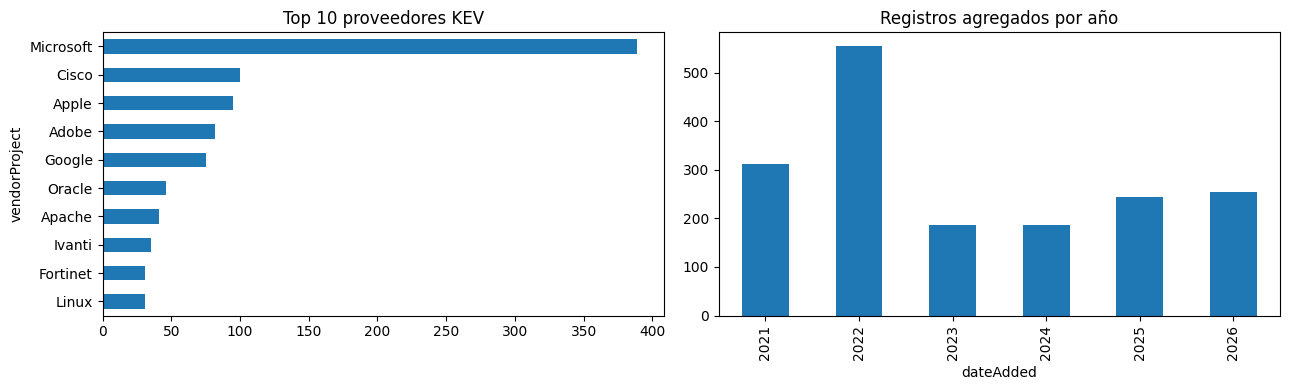

Interpretación: la frecuencia refleja presencia en KEV, NO prevalencia total ni riesgo individual.


In [4]:
print('Dimensiones:',df.shape)
print('Columnas:',list(df.columns))
print('Duplicados CVE:',df['cveID'].duplicated().sum())
print('Nulos (%):'); display((df.isna().mean()*100).round(1).sort_values(ascending=False).head(12).to_frame('porcentaje'))
fig,axs=plt.subplots(1,2,figsize=(13,4))
df['vendorProject'].value_counts().head(10).sort_values().plot.barh(ax=axs[0],title='Top 10 proveedores KEV')
pd.to_datetime(df['dateAdded'],errors='coerce').dt.year.value_counts().sort_index().plot.bar(ax=axs[1],title='Registros agregados por año')
plt.tight_layout(); plt.show()
print('Interpretación: la frecuencia refleja presencia en KEV, NO prevalencia total ni riesgo individual.')

### EDA ampliado: uso en ransomware, plazos y temporalidad
Estos gráficos representan **registros del catálogo KEV**, no la totalidad de vulnerabilidades existentes. Las fechas de incorporación no equivalen a fechas de explotación. Se excluyen valores ausentes cuando corresponda.


In [ ]:
# EDA adicional: gráficos calculados sobre la instantánea descargada
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
# Etiquetas reales de ransomware (puede existir Unknown)
col='knownRansomwareCampaignUse'
if col in df.columns:
    ransomware=df[col].fillna('Sin dato').astype(str).value_counts()
    ransomware.plot(kind='bar', ax=axs[0], title='Uso en campañas ransomware (KEV)', rot=35)
    axs[0].set_ylabel('Registros')
else:
    axs[0].text(0.5,0.5,'Columna no disponible',ha='center'); axs[0].set_axis_off()
# Distribución de vencimientos de remediación, no SLA calculado
if 'dueDate' in df.columns:
    venc=pd.to_datetime(df['dueDate'],errors='coerce').dropna()
    if not venc.empty:
        venc.dt.year.value_counts().sort_index().plot.bar(ax=axs[1],title='Fechas de vencimiento por año')
        axs[1].set_ylabel('Registros')
    else: axs[1].text(0.5,0.5,'Sin fechas válidas',ha='center')
else: axs[1].text(0.5,0.5,'Columna no disponible',ha='center')
# Evolución mensual de entradas al catálogo: últimos 24 meses observados
fecha=pd.to_datetime(df['dateAdded'],errors='coerce').dropna()
if not fecha.empty:
    mensuales=fecha.dt.to_period('M').value_counts().sort_index().tail(24)
    mensuales.index=mensuales.index.astype(str)
    mensuales.plot.line(marker='o',ax=axs[2],title='Altas KEV — últimos 24 meses observados')
    axs[2].tick_params(axis='x',labelrotation=70)
    axs[2].set_ylabel('Registros añadidos')
else: axs[2].text(0.5,0.5,'Sin fechas válidas',ha='center')
plt.tight_layout()
plt.savefig(WORK/'eda_kev_ampliado.png',dpi=160,bbox_inches='tight')
plt.show()


## 2. Construcción del servidor MCP real
Servidor independiente con tres herramientas: `buscar_vulnerabilidades`, `consultar_cve`, `resumen_proveedores`. Retorna JSON con identificadores CVE y enlace de origen. No implementa escaneo ni explotación. Al usar **cliente y servidor separados mediante stdio** se evidencia el protocolo MCP.

In [5]:
SERVER_CODE = r'''import json
from pathlib import Path
from mcp.server.fastmcp import FastMCP
mcp=FastMCP('CyberMCP_KEV')
base=Path(__file__).resolve().parent
source=json.loads((base/'cisa_kev_snapshot.json').read_text(encoding='utf-8'))
records=source['vulnerabilities']
url='https://www.cisa.gov/known-exploited-vulnerabilities-catalog'
def compact(x):
    keys=['cveID','vendorProject','product','vulnerabilityName','shortDescription','requiredAction','dueDate','dateAdded','knownRansomwareCampaignUse','notes']
    return {k:x.get(k,'') for k in keys} | {'source_url':url,'source_id':x.get('cveID','')}
@mcp.tool()
def consultar_cve(cve_id: str) -> str:
    """Busca coincidencia exacta de un CVE en el catálogo KEV."""
    cve_id=cve_id.strip().upper()
    matches=[compact(x) for x in records if x.get('cveID','').upper()==cve_id]
    return json.dumps({'found':bool(matches),'records':matches,'catalog':'CISA KEV','source_url':url},ensure_ascii=False)
@mcp.tool()
def buscar_vulnerabilidades(query: str, limit: int=5) -> str:
    """Busca textos por coincidencia de términos en entradas CISA KEV."""
    import re
    tokens=set(re.findall(r'[\w.-]{3,}',query.lower()))
    scored=[]
    for x in records:
        searchable=' '.join(str(x.get(k,'')) for k in ['cveID','vendorProject','product','vulnerabilityName','shortDescription','requiredAction']).lower()
        score=sum(1 for t in tokens if t in searchable)
        if score: scored.append((score,x))
    scored.sort(key=lambda z:(-z[0],z[1].get('cveID','')))
    return json.dumps({'records':[compact(x) for _,x in scored[:max(1,min(limit,10))]],'total_matches':len(scored),'source_url':url},ensure_ascii=False)
@mcp.tool()
def resumen_proveedores(limit: int=5) -> str:
    """Devuelve conteos descriptivos de proveedores presentes en KEV."""
    from collections import Counter
    counts=Counter(x.get('vendorProject','No informado') for x in records)
    return json.dumps({'ranking':counts.most_common(max(1,min(limit,15))),'total_records':len(records),'source_url':url},ensure_ascii=False)
if __name__=='__main__':
    mcp.run(transport='stdio')
'''
(WORK/'cybermcp_server.py').write_text(SERVER_CODE,encoding='utf-8')
print('Servidor MCP creado:',WORK/'cybermcp_server.py')

Servidor MCP creado: /content/cybermcp/cybermcp_server.py


## 3. Cliente MCP — descubrimiento y llamada real
La conexión se establece por subproceso `stdio` y MCP `ClientSession`, incluyendo inicialización y `list_tools`; la salida de herramientas debe conservar referencias.

In [8]:
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client
import os

# Pasamos una copia de os.environ para asegurar que el proceso hijo herede correctamente el entorno sin chocar con los flujos virtuales de IPython/Colab
PARAMS=StdioServerParameters(command=sys.executable,args=[str(WORK/'cybermcp_server.py')],env=dict(os.environ))
async def usar_mcp(nombre,args):
    # Abrimos un archivo físico para redirigir el log de errores (errlog) y evitar el fallo con .fileno() de sys.stderr en Colab
    with open(WORK/'mcp_stderr.log', 'a') as err_file:
        async with stdio_client(PARAMS, errlog=err_file) as (read,write):
            async with ClientSession(read,write) as session:
                await session.initialize()
                herramientas=await session.list_tools()
                nombres=[t.name for t in herramientas.tools]
                if nombre not in nombres: raise ValueError(f'Herramienta no disponible: {nombre}; existentes {nombres}')
                result=await session.call_tool(nombre,arguments=args)
                if result.isError: raise RuntimeError(str(result.content))
                texts=[c.text for c in result.content if getattr(c,'type',None)=='text']
                if not texts: raise RuntimeError('La herramienta MCP no devolvió texto')
                return json.loads(texts[0])

print('Prueba MCP exacta:')
ejemplo_cve=df.iloc[0]['cveID']
prueba=await usar_mcp('consultar_cve',{'cve_id':ejemplo_cve})
assert prueba['found'] and prueba['records'][0]['cveID']==ejemplo_cve
print(json.dumps(prueba,ensure_ascii=False,indent=2)[:1700])

Prueba MCP exacta:
{
  "found": true,
  "records": [
    {
      "cveID": "CVE-2015-5477",
      "vendorProject": "ISC",
      "product": "BIND",
      "vulnerabilityName": " ISC BIND Data Processing Errors Vulnerability",
      "shortDescription": "ISC BIND contains a data processing errors vulnerability that could allow remote attackers to cause a denial of service via TKEY queries.",
      "requiredAction": "Apply mitigations in accordance with vendor instructions, ensuring compliance with CISA’s BOD 26-04 Prioritizing Security Updates Based on Risk (see URL in Notes) guidance and CISA’s “Forensics Triage Requirements” (see URL in Notes). Follow applicable BOD 26-04 guidance for cloud services or discontinue use of the product if mitigations are unavailable. Stakeholders are responsible for evaluating each asset's internet exposure and ensuring adherence to BOD 26-04 patching guidelines.",
      "dueDate": "2026-10-11",
      "dateAdded": "2026-10-08",
      "knownRansomwareCampaign

## 4. LLM local Transformers sobre GPU T4
Modelo pequeño para demostrar fluidez sin Ollama. No es un agente autónomo: **LangChain enruta herramientas y compone un pipeline reproducible**, después el LLM redacta a partir de los resultados MCP. Esto distingue de forma explícita las funciones de cada componente.

In [9]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODEL_ID='Qwen/Qwen2.5-0.5B-Instruct'
t0=time.perf_counter()
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,torch_dtype=torch.float16,device_map='auto')
model.eval()
print('Modelo listo:',MODEL_ID,'dispositivo:',model.device,'carga s:',round(time.perf_counter()-t0,1))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo listo: Qwen/Qwen2.5-0.5B-Instruct dispositivo: cuda:0 carga s: 18.6


In [10]:
def generar_llm(pregunta,contexto,usar_contexto=True,max_new_tokens=170):
    if usar_contexto:
        sistema=('Eres un asistente académico sobre vulnerabilidades. Responde SOLO con evidencia proporcionada. '
                 'No inventes CVE ni detalles ausentes. Si no hay registro, di que no aparece en el catálogo consultado, '
                 'sin asegurar que el CVE no existe. Incluye identificadores CVE y la fuente suministrada. '
                 'No incluyas instrucciones de explotación.')
        user=f'Pregunta: {pregunta}\n\nContexto de herramientas MCP (datos):\n{contexto[:6500]}'
    else:
        sistema='Eres un asistente educativo de ciberseguridad. Si desconoces algo, indícalo. No proporciones instrucciones ofensivas.'
        user=pregunta
    mensajes=[{'role':'system','content':sistema},{'role':'user','content':user}]
    entrada=tokenizer.apply_chat_template(mensajes,tokenize=False,add_generation_prompt=True)
    inputs=tokenizer(entrada,return_tensors='pt',truncation=True,max_length=2800).to(model.device)
    t0=time.perf_counter()
    with torch.inference_mode():
        ids=model.generate(**inputs,max_new_tokens=max_new_tokens,do_sample=False,pad_token_id=tokenizer.eos_token_id)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    respuesta=tokenizer.decode(ids[0][inputs['input_ids'].shape[1]:],skip_special_tokens=True).strip()
    return respuesta,round(time.perf_counter()-t0,3)
print('Smoke test LLM:',generar_llm('Responde solo LISTO.','',False,max_new_tokens=16))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Smoke test LLM: ('LISTO.', 1.823)


## 5. LangChain: enrutamiento → MCP → generación fundamentada
`RunnableLambda` integra la arquitectura y permite instrumentación; no se presenta como agente LangChain con planificación automática. Las referencias se agregan **desde los registros devueltos** independientemente de cómo redacte el modelo.

In [11]:
from langchain_core.runnables import RunnableLambda
from langchain_core.tools import StructuredTool
CATALOG_LINK='https://www.cisa.gov/known-exploited-vulnerabilities-catalog'
def planificar(p):
    q=p['question']; m=re.search(r'CVE-\d{4}-\d{4,}',q,re.I)
    if m: tool,args='consultar_cve',{'cve_id':m.group(0).upper()}
    elif any(x in q.lower() for x in ['proveedores','fabricantes','vendors','top 5','top cinco']):
        tool,args='resumen_proveedores',{'limit':p.get('top_k',5)}
    else: tool,args='buscar_vulnerabilidades',{'query':q,'limit':p.get('top_k',5)}
    return dict(p,tool=tool,args=args)
async def recuperar(p):
    t0=time.perf_counter()
    data=await usar_mcp(p['tool'],p['args'])
    return dict(p,data=data,retrieval_s=round(time.perf_counter()-t0,3))
def responder(p):
    data=p['data']; recs=data.get('records',[])
    if p['tool']=='consultar_cve' and not data.get('found'):
        answer='No encuentro ese identificador en la instantánea CISA KEV consultada. Esto NO significa que el CVE no exista; solamente que no figura en este catálogo.'
        gen_s=0.0
    elif p['tool']=='buscar_vulnerabilidades' and not recs:
        answer='No se encontraron entradas que coincidan con esta búsqueda en el catálogo descargado.';gen_s=0.0
    else:
        answer,gen_s=generar_llm(p['question'],json.dumps(data,ensure_ascii=False),p.get('with_context',True))
    refs=sorted(set(x.get('source_id','') for x in recs if x.get('source_id')))
    if p['tool']=='resumen_proveedores': refs=['CISA KEV (resumen agregado)']
    fuentes=f'\n\n**Fuente consultada:** [Catálogo oficial CISA KEV]({CATALOG_LINK})'
    if refs: fuentes+='\n**Entradas recuperadas:** '+', '.join(refs)
    return {'answer':answer+fuentes,'retrieval_s':p['retrieval_s'],'generation_s':gen_s,'tool':p['tool'],'sources':refs,'raw':data}
chain=RunnableLambda(planificar) | RunnableLambda(recuperar) | RunnableLambda(responder)
# Herramienta LangChain declarada explícitamente (además del cliente MCP real):
async def consulta_kev_tool(cve_id:str)->str:
    """Consulta exacta a un CVE de CISA KEV a través de MCP."""
    return json.dumps(await usar_mcp('consultar_cve',{'cve_id':cve_id}),ensure_ascii=False)
langchain_tool=StructuredTool.from_function(coroutine=consulta_kev_tool,name='consulta_kev_mcp',description='Consulta exacta CVE mediante MCP')
print('Herramienta LangChain:',langchain_tool.name)
res=await chain.ainvoke({'question':f'¿Qué acción se indica para {ejemplo_cve}?','top_k':3,'with_context':True})
print(res['answer'][:1600]); print('Rendimiento:',res['retrieval_s'],res['generation_s'])

Herramienta LangChain: consulta_kev_mcp
El ID del CVE-2015-5477 es CVE-2015-5477. Según los datos proporcionados, la acción recomendada para este vulnerabilidad es:

"Apply mitigations in accordance with vendor instructions, ensuring compliance with CISA’s BOD 26-04 Prioritizing Security Updates Based on Risk (see URL in Notes) guidance and CISA’s “Forensics Triage Requirements” (see URL in Notes). Follow applicable BOD 26-04 guidance for cloud services or discontinue use of the product if mitigations are unavailable."

Esta información sugiere que la mitigación adecuada para este problema es aplicar las medidas solicitadas por la CISA, basándose en las directrices de priorización y guía de triaje.

**Fuente consultada:** [Catálogo oficial CISA KEV](https://www.cisa.gov/known-exploited-vulnerabilities-catalog)
**Entradas recuperadas:** CVE-2015-5477
Rendimiento: 4.095 5.178


## 6. Evaluación estructurada de las herramientas
Métricas objetivas: exactitud de búsqueda exacta, abstención ante un identificador ausente, tiempo MCP. Se prueba **recuperación**, no se asume que la redacción del LLM es factualmente perfecta.

In [12]:
ids=df['cveID'].drop_duplicates().head(12).tolist()
experimentos=[]
for cve in ids+['CVE-2099-999999']:
    t=time.perf_counter(); r=await usar_mcp('consultar_cve',{'cve_id':cve})
    esperado=cve in set(ids); correcto=(r['found']==esperado and (not esperado or r['records'][0]['cveID']==cve))
    experimentos.append({'cve':cve,'esperado_presente':esperado,'correcto':correcto,'latencia_s':time.perf_counter()-t})
eval_df=pd.DataFrame(experimentos); display(eval_df)
print('Exactitud de la herramienta exacta (muestra):',round(eval_df.correcto.mean(),3))
print('Mediana latencia MCP (s):',round(eval_df.latencia_s.median(),3))
eval_df.to_csv(WORK/'evaluacion_busqueda_exacta.csv',index=False)

,cve,esperado_presente,correcto,latencia_s
0,CVE-2015-5477,True,True,6.371077
1,CVE-2016-3081,True,True,4.044918
2,CVE-2023-22894,True,True,3.646084
3,CVE-2021-3199,True,True,6.106690
4,CVE-2015-3306,True,True,3.636191
5,CVE-2026-88779,True,True,3.639995
6,CVE-2026-102490,True,True,6.715820
7,CVE-2026-102489,True,True,3.863766
8,CVE-2026-104286,True,True,2.844091
9,CVE-2026-76504,True,True,2.997574


Exactitud de la herramienta exacta (muestra): 1.0
Mediana latencia MCP (s): 3.64


### Evaluación visual de herramientas MCP
Se grafican tiempos reales de las llamadas exactas y proporción de respuestas correctas. Esta muestra contiene 12 CVE presentes y una consulta deliberadamente ausente; **no equivale a exactitud general**.


In [ ]:
# Gráficos derivados de eval_df; no ejecutar antes de las pruebas MCP
from matplotlib.ticker import PercentFormatter
fig,axs=plt.subplots(1,2,figsize=(13,4))
orden=eval_df.sort_values('latencia_s',ascending=True)
axs[0].barh(orden['cve'],orden['latencia_s'])
axs[0].set_xlabel('Segundos');axs[0].set_title('Latencia por consulta MCP exacta')
axs[1].bar(['Correctas','Incorrectas'],[int(eval_df['correcto'].sum()),int((~eval_df['correcto'].astype(bool)).sum())])
axs[1].set_ylabel('Número de consultas');axs[1].set_title('Resultado de pruebas controladas MCP')
for i,v in enumerate([int(eval_df['correcto'].sum()),int((~eval_df['correcto'].astype(bool)).sum())]): axs[1].text(i,v+0.05,str(v),ha='center')
plt.tight_layout();plt.savefig(WORK/'metricas_mcp.png',dpi=160,bbox_inches='tight');plt.show()
print('P50/P95 latencia MCP:',round(eval_df.latencia_s.quantile(.5),3),round(eval_df.latencia_s.quantile(.95),3),'s')


## 7. Experimento comparativo de recuperación: TF-IDF vs búsqueda textual MCP
Esta comparación evalúa el **ranking de recuperación de documentos** para consultas sintéticas derivadas de una selección determinista del catálogo. Al usar las mismas descripciones para construir algunas consultas, los resultados están sujetos a sesgo favorable al ranking lexical; no constituyen evaluación externa independiente.

,query,target,hit_1,hit_3,hit_5
0,ISC BIND,CVE-2015-5477,1,1,1
1,WordPress Core,CVE-2026-87902,0,1,1
2,ConnectWise ScreenConnect,CVE-2026-84869,0,1,1
3,BerriAI LiteLLM,CVE-2026-59822,0,1,1
4,Linux Kernel,CVE-2022-0995,0,1,1
5,Microsoft Windows Ancillary Function Driver fo...,CVE-2026-68820,1,1,1
6,Langflow Langflow,CVE-2026-0770,0,1,1
7,Langflow Langflow,CVE-2026-55255,0,0,1
8,Oracle PeopleSoft Enterprise PeopleTools,CVE-2026-35273,1,1,1
9,Daemon Daemon Tools Lite,CVE-2026-8398,1,1,1


TF-IDF Hit@1 / Hit@3 / Hit@5: 0.4 0.9 1.0


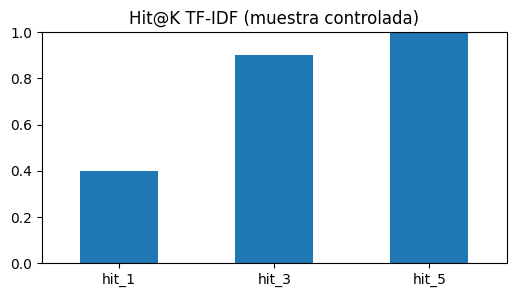

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
sample=df.head(min(600,len(df))).copy().reset_index(drop=True)
texts=(sample['vendorProject'].fillna('')+' '+sample['product'].fillna('')+' '+sample['vulnerabilityName'].fillna('')+' '+sample['shortDescription'].fillna('')).tolist()
vectorizer=TfidfVectorizer(ngram_range=(1,2),max_features=20000,stop_words='english')
X=vectorizer.fit_transform(texts)
queries=[]
for ix in range(0,min(150,len(sample)),15):
    row=sample.iloc[ix]
    q=str(row['vendorProject'])+' '+str(row['product'])
    queries.append((q,row['cveID']))
rows=[]
for q,target in queries:
    sims=cosine_similarity(vectorizer.transform([q]),X).ravel()
    top_indices=np.argsort(-sims)[:5]
    retrieved=sample.iloc[top_indices]['cveID'].tolist()
    rows.append({'query':q,'target':target,'hit_1':int(target in retrieved[:1]),'hit_3':int(target in retrieved[:3]),'hit_5':int(target in retrieved[:5])})
tfidf_eval=pd.DataFrame(rows)
display(tfidf_eval)
print('TF-IDF Hit@1 / Hit@3 / Hit@5:',*[round(tfidf_eval[c].mean(),3) for c in ['hit_1','hit_3','hit_5']])
tfidf_eval.to_csv(WORK/'evaluacion_tfidf.csv',index=False)
fig,ax=plt.subplots(figsize=(6,3)); tfidf_eval[['hit_1','hit_3','hit_5']].mean().plot.bar(ax=ax,title='Hit@K TF-IDF (muestra controlada)',rot=0);ax.set_ylim(0,1);plt.show()

### Diagnóstico adicional de calidad de recuperación
Visualiza éxito de búsqueda en cada consulta sintética y la diferencia entre Hit@1 y Hit@5. **Advertencia metodológica:** las consultas están derivadas del mismo catálogo indexado; estos resultados no prueban generalización a preguntas reales.


In [ ]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
metricas=tfidf_eval[['hit_1','hit_3','hit_5']].mean().rename({'hit_1':'Hit@1','hit_3':'Hit@3','hit_5':'Hit@5'})
metricas.plot.bar(ax=axs[0],rot=0,title='Recuperación TF-IDF — Hit@K')
axs[0].set_ylim(0,1.05);axs[0].set_ylabel('Proporción de consultas')
for i,v in enumerate(metricas): axs[0].text(i,min(v+.02,1.02),f'{v:.1%}',ha='center')
mat=tfidf_eval[['hit_1','hit_3','hit_5']].to_numpy(dtype=float)
axs[1].imshow(mat,aspect='auto',cmap='Blues',vmin=0,vmax=1)
axs[1].set_xticks(range(3),['Top-1','Top-3','Top-5'])
axs[1].set_yticks(range(len(tfidf_eval)),[f'Q{i+1}' for i in range(len(tfidf_eval))])
axs[1].set_title('Aciertos por consulta sintética')
plt.tight_layout();plt.savefig(WORK/'recuperacion_tfidf.png',dpi=160,bbox_inches='tight');plt.show()


## 8. Comparación LLM sin herramientas / con herramientas
Se muestran respuestas a una pregunta real **con y sin** contexto. Una comparación automática basada en longitud no mide fidelidad: se adjunta una rúbrica de evaluación humana.

In [14]:
pregunta=f'¿Qué dice CISA sobre {ejemplo_cve} y qué acción solicita?'
base,base_t=generar_llm(pregunta,'',False,max_new_tokens=120)
con=await chain.ainvoke({'question':pregunta,'top_k':3,'with_context':True})
print('SIN MCP (',base_t,'s):\n',base)
print('\nCON MCP + LangChain (recuperación',con['retrieval_s'],'s, generación',con['generation_s'],'s):\n',con['answer'])
print('\nCalifica manualmente: exactitud, soporte documental, abstención, claridad (1 a 5).')

SIN MCP ( 3.319 s):
 CISA (Center for Internet Security) no ha publicado información específica sobre el código fuente o vulnerabilidades específicas mencionadas en CVE-2015-5477. Sin embargo, la CVE (Common Vulnerabilities and Exposures) es una organización internacional que proporciona información sobre los problemas de seguridad en software. Si tienes alguna pregunta específica sobre cómo se manejó este problema o si hay algún otro tema específico que necesites ayuda con, estaré encantado de ayudarte.

CON MCP + LangChain (recuperación 2.912 s, generación 5.254 s):
 El CVE-2015-5477 se refiere a una vulnerabilidad conocida en BIND, un servicio de red de dominio utilizado por servicios de correo electrónico y otros servidores de datos. Según la información proporcionada, esta vulnerabilidad afecta al producto BIND, específicamente:

- **Vendor Project**: ISC (Institute of Systems and Services)
- **Product**: BIND
- **Vulnerability Name**: ISC BIND Data Processing Errors Vulnerability

### Comparación de tiempos del LLM y la recuperación MCP
Gráfico del **único caso medido** en la sección anterior. No representa un benchmark estadístico hasta repetir la prueba sobre más consultas y condiciones equivalentes.


In [ ]:
# Mediciones procedentes de la comparación de generación ejecutada anteriormente
tiempo_mcp=float(con['retrieval_s'])
tiempo_llm_mcp=float(con['generation_s'])
tiempo_sin_mcp=float(base_t)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(['Sin herramientas','Con MCP + LangChain'],[tiempo_sin_mcp,tiempo_mcp+tiempo_llm_mcp])
axs[0].set_title('Tiempo total observado — 1 consulta')
axs[0].set_ylabel('Segundos')
axs[1].bar(['Recuperación MCP','Generación LLM'],[tiempo_mcp,tiempo_llm_mcp])
axs[1].set_title('Desglose respuesta con MCP')
axs[1].set_ylabel('Segundos')
plt.tight_layout();plt.savefig(WORK/'latencia_generacion_mcp.png',dpi=160,bbox_inches='tight');plt.show()


## 9. Chatbot Gradio y vídeo obligatorio
Mostrar esta celda ejecutándose y dos interacciones en menos de 2 minutos. Se usa `share=True` para el túnel temporal público: **no introduzcas datos privados, contraseñas o archivos internos**. Los enlaces pueden expirar. La herramienta de ranking devuelve conteos, no vulnerabilidades individuales.

In [15]:
import gradio as gr
async def chat(message,history,top_k):
    try:
        res=await chain.ainvoke({'question':message,'top_k':int(top_k),'with_context':True})
        return res['answer']+f"\n\n*MCP: {res['tool']} · recuperación: {res['retrieval_s']:.2f} s · generación: {res['generation_s']:.2f} s*"
    except Exception as exc:
        return f'Error controlado: {type(exc).__name__}: {str(exc)[:350]}. Comprueba servidor, dataset y GPU.'
demo=gr.ChatInterface(fn=chat,type='messages',additional_inputs=[gr.Slider(1,5,value=3,step=1,label='Top-K')],title='CyberMCP V1 | CISA KEV + MCP + LangChain',description='Consulta académica del catálogo público CISA KEV. Las respuestas incluyen fuente y CVE recuperados.',examples=[[f'¿Qué recomienda CISA para {ejemplo_cve}?',3],['¿Cuáles son los principales proveedores en el catálogo?',3],['¿Qué dice CISA sobre CVE-2099-999999?',3]])
demo.launch(share=True,debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://83f8a8b415193fbecc.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Hallazgos, límites y reflexión académica (completar con resultados reales)
1. **Problema:** acceso verificable a referencias públicas de vulnerabilidades explotadas, sin afirmar cobertura completa de CVE.
2. **MCP:** herramientas declaradas en servidor aislado y descubiertas con `ClientSession`, no llamadas simuladas.
3. **LangChain:** `RunnableLambda` compone enrutamiento, llamada MCP y generación; `StructuredTool` ejemplifica la representación LangChain. **No es** un agente que planifica libremente.
4. **EDA:** interpretar los proveedores y fecha agregada, sin confundir frecuencias con probabilidad de explotación.
5. **Medición:** copiar cifras generadas en las secciones 6–8 y discutir debilidades del conjunto de prueba.
6. **Límites:** tamaño pequeño de modelo, descarga dependiente de red, sesgo de CISA KEV, respuestas probabilísticas, y la necesidad de revisar manualmente las salidas del LLM.
7. **Trabajo futuro:** recuperación semántica, reranking, grounding automático y evaluación humana ciega; no atribuir mejoras sin medirlas.

**Guion audiovisual:** incluida plantilla `GUION_VIDEO_2_MIN.md` en el paquete. **Publicación:** exportar el cuaderno y las tablas, enlazar al repositorio, adjuntar el vídeo de 2 minutos en el campus virtual.